# 01 · Data understanding

Schema, quality checks, cadence and the question that decides the VM-count target: do all VMs share the same timestamps?

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") if Path("../challenge_data").exists() else Path(".")
DATA, FIG = ROOT / "challenge_data", ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
from cwfc.io import check_data, load_metadata, load_readings, print_report
from cwfc.targets import build_targets

In [2]:
readings = load_readings(DATA)
meta = load_metadata(DATA)
readings.info(show_counts=True)
meta.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 1340000 entries, 0 to 1339999
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   timestamp  1340000 non-null  int64  
 1   vm_id      1340000 non-null  str    
 2   min_cpu    1340000 non-null  float64
 3   max_cpu    1340000 non-null  float64
 4   avg_cpu    1340000 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 51.1 MB
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vm_id                 10000 non-null  str    
 1   subscription_id       10000 non-null  str    
 2   deployment_id         10000 non-null  str    
 3   timestamp_vm_created  10000 non-null  int64  
 4   timestamp_vm_deleted  10000 non-null  int64  
 5   max_cpu               10000 non-null  float64
 6   avg_cpu               10000 non-null

In [3]:
report = check_data(readings, meta)
print_report(report)

rows                       1340000
vms                        10000
timestamps                 134
first_ts                   0
last_ts                    39900
cadence_values             [300]
duplicate_rows             0
missing_values             {'timestamp': 0, 'vm_id': 0, 'min_cpu': 0, 'max_cpu': 0, 'avg_cpu': 0}
cpu_out_of_range           0
min_gt_avg                 0
avg_gt_max                 0
vms_per_ts_min             10000
vms_per_ts_max             10000
obs_per_vm_min             134
obs_per_vm_max             134
all_vms_share_timestamps   True
vms_without_metadata       0
metadata_without_readings  0
duplicate_metadata         0


Every check comes back clean: no duplicates, no missing values, every gap is exactly 300 s, CPU stays in [0, 100] with `min <= avg <= max`, and the readings and metadata cover the same 10,000 VMs.

In [4]:
per_ts = readings.groupby("timestamp")["vm_id"].nunique()
per_vm = readings.groupby("vm_id")["timestamp"].agg(["min", "max", "count"])
print(per_ts.describe())
print(per_vm.describe())

count      134.0
mean     10000.0
std          0.0
min      10000.0
25%      10000.0
50%      10000.0
75%      10000.0
max      10000.0
Name: vm_id, dtype: float64
           min      max    count
count  10000.0  10000.0  10000.0
mean       0.0  39900.0    134.0
std        0.0      0.0      0.0
min        0.0  39900.0    134.0
25%        0.0  39900.0    134.0
50%        0.0  39900.0    134.0
75%        0.0  39900.0    134.0
max        0.0  39900.0    134.0


**All 10,000 VMs report at all 134 timestamps.** Inside the window `active_vm_count` is a flat 10,000. The selection rule (only VMs with a complete trace qualified) causes this, so it tells us nothing about real fleet churn. Persistence is exact for this target, and no model can beat it here.

In [5]:
life = meta[["timestamp_vm_created", "timestamp_vm_deleted"]].describe().T
print(life)
end = readings["timestamp"].max()
deleted = meta["timestamp_vm_deleted"]
print("created at trace start:", (meta["timestamp_vm_created"] == 0).mean())
print("alive until end of 30-day trace:", (deleted == deleted.max()).mean().round(3))
print("deleted within 2h after the window:", int((deleted <= end + 2 * 3600).sum()))

                        count       mean         std      min        25%  \
timestamp_vm_created  10000.0  0.000e+00       0.000      0.0  0.000e+00   
timestamp_vm_deleted  10000.0  2.290e+06  708100.834  40500.0  2.591e+06   

                            50%        75%        max  
timestamp_vm_created  0.000e+00  0.000e+00  0.000e+00  
timestamp_vm_deleted  2.591e+06  2.591e+06  2.591e+06  
created at trace start: 1.0
alive until end of 30-day trace: 0.821
deleted within 2h after the window: 13


The metadata covers the full 30-day trace. Every VM already existed when the trace started, and 82% were still running at its end. Deletion times all fall after the 11-hour window, and using them would leak future information, so they are only descriptive here and never a feature.

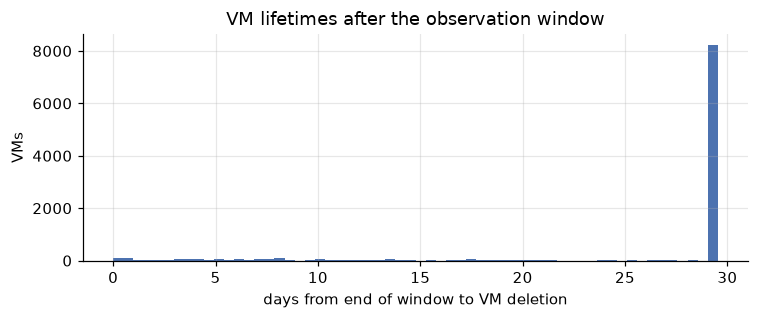

In [6]:
fig, ax = plt.subplots(figsize=(7, 3))
days = (deleted - end) / 86400
ax.hist(days, bins=60, color="#4c72b0")
ax.set_xlabel("days from end of window to VM deletion")
ax.set_ylabel("VMs")
ax.set_title("VM lifetimes after the observation window")
fig.tight_layout(); fig.savefig(FIG / "vm_deletion.png")

A small set of VMs is deleted within hours of the window ending. In a live fleet this churn would show up in `active_vm_count`; the curated sample can't show it.

In [7]:
counts = pd.DataFrame({c: meta[c].value_counts() for c in ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]})
counts

,vm_category,virtual_core_bucket,memory_gb_bucket
2,NaN,7534.0,3904.0
24,NaN,62.0,NaN
32,NaN,NaN,1383.0
4,NaN,1908.0,2475.0
64,NaN,NaN,82.0
8,NaN,486.0,2146.0
>24,NaN,10.0,NaN
>64,NaN,NaN,10.0
Delay-insensitive,6180.0,NaN,NaN
Interactive,3091.0,NaN,NaN


In [8]:
pd.crosstab(meta["vm_category"], meta["virtual_core_bucket"], margins=True)

virtual_core_bucket,2,24,4,8,>24,All
vm_category,,,,,,
Delay-insensitive,4892,34,1044,206,4,6180
Interactive,2212,21,653,199,6,3091
Unknown,430,7,211,81,0,729
All,7534,62,1908,486,10,10000


The sample is stratified on category × core bucket. Most VMs are small: 75% have 2 cores. The `>24` bucket holds only 10 VMs, so its segment statistics are noisy.

In [9]:
series = build_targets(readings)
print(series.head())
print("imputed timestamps:", int(series["imputed"].sum()))
series[["active_vm_count", "aggregate_cpu_utilization"]].describe()

   timestamp  active_vm_count  aggregate_cpu_utilization  imputed
0          0          10000.0                      9.397    False
1        300          10000.0                      9.354    False
2        600          10000.0                      9.454    False
3        900          10000.0                      9.224    False
4       1200          10000.0                      9.144    False
imputed timestamps: 0


,active_vm_count,aggregate_cpu_utilization
count,134.0,134.000
mean,10000.0,9.388
std,0.0,0.195
min,10000.0,8.984
25%,10000.0,9.251
50%,10000.0,9.367
75%,10000.0,9.486
max,10000.0,9.912


Targets are built on the full 5-minute grid before the 110/24 split. `aggregate_cpu_utilization` is the mean of per-VM `avg_cpu` over the VMs present at each timestamp. Missing grid slots would be interpolated and flagged, but this release has none. Each target value depends only on readings from its own timestamp, so building the series before splitting can't leak.